In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister,
    transpile,
)

from qiskit.circuit.library import StatePreparation
from qiskit_aer import AerSimulator

# CROSS-COVARIANCE

In [2]:
# ============================================================
# SETTINGS
# ============================================================

N_PARAMETERS = 5
N_SAMPLES = 64

n = int(np.log2(N_SAMPLES))

shots = 100_000

In [3]:
# ============================================================
# WAVELET MODEL
# ============================================================

start_time = 0
seg_length = 10
sample_rate = 4096

t_range = np.arange(
    start_time,
    start_time + seg_length,
    1 / sample_rate
)


def morlet_gabor_wavelet(A, phi, f, t0, Q):

    omega = 2 * np.pi * f
    tau = Q / omega

    dt = t_range - t0

    return (
        A
        * np.exp(-dt**2 / tau**2)
        * np.cos(omega * dt + phi)
    )

In [4]:
# ============================================================
# RANDOM WAVELET
# ============================================================

def dynamic_wavelets():

    # Amplitude
    A = np.exp(
        np.random.uniform(
            -25 * np.log(2),
            -18 * np.log(2)
        )
    )

    # NOTE:
    # Original code used exp(uniform(...)) for phi,
    # which gives phi in [1, 2*pi], not uniform [0, 2*pi].
    # If you actually want uniform phase, use this:
    phi = np.random.uniform(0, 2 * np.pi)

    t0 = np.random.choice(
        [
            2.0,
            2.0 + 1 / 4096
        ]
    )

    funif = np.random.uniform(
        0,
        sample_rate * 2
    )

    fnorm = np.random.normal(
        100,
        0.0001
    )

    Qunif = np.random.uniform(
        0.1,
        40
    )

    Qnorm = np.random.normal(
        5,
        0.0001
    )

    Q = (
        0.80 * Qnorm
        + 0.20 * Qunif
    )

    f = (
        0.80 * fnorm
        + 0.20 * funif
    )

    rand_wavelet = morlet_gabor_wavelet(
        A,
        phi,
        f,
        t0,
        Q
    )

    parameters = np.array(
        [
            A,
            phi,
            t0,
            f,
            Q
        ],
        dtype=float
    )

    return rand_wavelet, parameters


# ============================================================
# CLASSICAL COVARIANCE CALCULATIONS
# ============================================================

def classical_covariances(
    parameters_1,
    parameters_2
):
    """
    Parameters
    ----------
    parameters_1 : shape (N, 5)
    parameters_2 : shape (N, 5)

    Rows are paired samples.

    Returns
    -------
    standard_covariance
        Centered sample cross-covariance.

    zero_mean_covariance
        Uncentered cross second moment.

    cs_covariance
        Element-wise Cauchy-Schwarz upper bound.

    global_cs_bound
        Global vector/Frobenius Cauchy-Schwarz bound.

    means_1, means_2
        Sample means.

    std1, std2
        Sample standard deviations.
    """

    X = np.asarray(parameters_1, dtype=float)
    Y = np.asarray(parameters_2, dtype=float)

    if X.shape != Y.shape:
        raise ValueError(
            "parameters_1 and parameters_2 must have "
            "the same shape."
        )

    if X.ndim != 2:
        raise ValueError(
            "Parameter arrays must be 2-dimensional."
        )

    N = X.shape[0]

    if N < 2:
        raise ValueError(
            "Need at least two samples."
        )

    # --------------------------------------------------------
    # Means
    # --------------------------------------------------------

    means_1 = np.mean(X, axis=0)
    means_2 = np.mean(Y, axis=0)

    # --------------------------------------------------------
    # Centered samples
    # --------------------------------------------------------

    Xc = X - means_1
    Yc = Y - means_2

    # --------------------------------------------------------
    # Standard sample cross-covariance
    #
    # C_ab =
    # 1/(N-1) sum_j
    # (X_ja - mean_Xa)
    # (Y_jb - mean_Yb)
    # --------------------------------------------------------

    standard_covariance = (
        Xc.T @ Yc
    ) / (N - 1)

    # --------------------------------------------------------
    # Zero-mean / uncentered cross moment
    #
    # Z_ab =
    # 1/(N-1) sum_j X_ja Y_jb
    # --------------------------------------------------------

    zero_mean_covariance = (
        X.T @ Y
    ) / (N - 1)

    # --------------------------------------------------------
    # Sample standard deviations
    # --------------------------------------------------------

    std1 = np.std(
        X,
        axis=0,
        ddof=1
    )

    std2 = np.std(
        Y,
        axis=0,
        ddof=1
    )

    # --------------------------------------------------------
    # Element-wise Cauchy-Schwarz bound
    #
    # |C_ab| <= std1[a] * std2[b]
    #
    # IMPORTANT:
    # No extra division by N-1 here.
    # --------------------------------------------------------

    cs_covariance = np.outer(
        std1,
        std2
    )

    # --------------------------------------------------------
    # Global Cauchy-Schwarz bound
    #
    # |sum_ij X_ij Y_ij|
    # <= ||X||_F ||Y||_F
    # --------------------------------------------------------

    global_cs_bound = (
        np.linalg.norm(X)
        * np.linalg.norm(Y)
        / (N - 1)
    )

    return {
        "standard": standard_covariance,
        "zero_mean": zero_mean_covariance,
        "cauchy_schwarz": cs_covariance,
        "global_cs": global_cs_bound,
        "mean_1": means_1,
        "mean_2": means_2,
        "std_1": std1,
        "std_2": std2,
    }

In [5]:
# ============================================================
# QUANTUM EXPECTATION ORACLE
# ============================================================

def append_probability_oracle(
    qc,
    index_qubits,
    target_qubit,
    values,
    minimum=None,
    maximum=None,
):
    """
    Coherent oracle

        |j>|0>
        ->
        |j>(
            sqrt(1-p_j)|0>
            +
            sqrt(p_j)|1>
        )

    where

        p_j = (values[j] - minimum)
              / (maximum - minimum)

    Therefore

        P(target=1) = E[p_j]

    when the index register is in

        sum_j sqrt(w_j)|j>.
    """

    values = np.asarray(
        values,
        dtype=float
    )

    if minimum is None:
        minimum = np.min(values)

    if maximum is None:
        maximum = np.max(values)

    if maximum <= minimum:

        # Constant function.
        # If value is exactly minimum=maximum,
        # expectation is known and no rotation is necessary.
        return

    n_index = len(index_qubits)

    for j, value in enumerate(values):

        p = (
            value - minimum
        ) / (
            maximum - minimum
        )

        p = np.clip(
            p,
            0.0,
            1.0
        )

        if np.isclose(p, 0.0):
            continue

        theta = (
            2
            * np.arcsin(
                np.sqrt(p)
            )
        )

        # ----------------------------------------------------
        # Convert |j> into |111...1>
        # ----------------------------------------------------

        for k in range(n_index):

            if ((j >> k) & 1) == 0:

                qc.x(
                    index_qubits[k]
                )

        # ----------------------------------------------------
        # Multi-controlled rotation
        # ----------------------------------------------------

        qc.mcry(
            theta,
            list(index_qubits),
            target_qubit
        )

        # ----------------------------------------------------
        # Undo basis-state selection
        # ----------------------------------------------------

        for k in range(n_index):

            if ((j >> k) & 1) == 0:

                qc.x(
                    index_qubits[k]
                )

In [6]:
# ============================================================
# QUANTUM MEAN CIRCUIT
# ============================================================

def build_mean_circuit(
    amplitudes,
    values
):
    """
    Returns a circuit whose final ancilla probability is

        P(M=1)
        =
        (E[X] - xmin)/(xmax-xmin).

    No measurement occurs inside this circuit.
    """

    amplitudes = np.asarray(
        amplitudes,
        dtype=complex
    )

    values = np.asarray(
        values,
        dtype=float
    )

    amplitudes = (
        amplitudes
        / np.linalg.norm(amplitudes)
    )

    N = len(amplitudes)

    n = int(np.log2(N))

    if 2**n != N:
        raise ValueError(
            "Number of amplitudes must be a power of two."
        )

    X = QuantumRegister(
        n,
        "index"
    )

    M = QuantumRegister(
        1,
        "mean"
    )

    qc = QuantumCircuit(
        X,
        M
    )

    # State preparation
    qc.append(
        StatePreparation(amplitudes),
        X
    )

    qc.barrier()

    xmin = np.min(values)
    xmax = np.max(values)

    append_probability_oracle(
        qc,
        X,
        M[0],
        values,
        xmin,
        xmax
    )

    return (
        qc,
        xmin,
        xmax
    )

In [7]:
# ============================================================
# QUANTUM CROSS MOMENT CIRCUIT
# ============================================================

def build_cross_moment_circuit(
    amplitudes,
    values_1,
    values_2
):
    """
    Constructs a fully coherent circuit for

        E[X Y]

    using

        P(A=1|j) = normalized X_j
        P(B=1|j) = normalized Y_j

    so that

        P(A=1,B=1)
        =
        E[normalized_X * normalized_Y].

    No measurement occurs until the final measurement
    performed by the caller.
    """

    amplitudes = np.asarray(
        amplitudes,
        dtype=complex
    )

    values_1 = np.asarray(
        values_1,
        dtype=float
    )

    values_2 = np.asarray(
        values_2,
        dtype=float
    )

    if len(values_1) != len(values_2):
        raise ValueError(
            "values_1 and values_2 must have "
            "the same length."
        )

    amplitudes = (
        amplitudes
        / np.linalg.norm(amplitudes)
    )

    N = len(amplitudes)

    n = int(np.log2(N))

    if 2**n != N:
        raise ValueError(
            "Number of amplitudes must be a power of two."
        )

    X = QuantumRegister(
        n,
        "index"
    )

    A = QuantumRegister(
        1,
        "A"
    )

    B = QuantumRegister(
        1,
        "B"
    )

    qc = QuantumCircuit(
        X,
        A,
        B
    )

    # --------------------------------------------------------
    # Prepare weighted sample-index state
    # --------------------------------------------------------

    qc.append(
        StatePreparation(amplitudes),
        X
    )

    qc.barrier()

    # --------------------------------------------------------
    # Encode X
    # --------------------------------------------------------

    xmin = np.min(values_1)
    xmax = np.max(values_1)

    append_probability_oracle(
        qc,
        X,
        A[0],
        values_1,
        xmin,
        xmax
    )

    qc.barrier()

    # --------------------------------------------------------
    # Encode Y
    # --------------------------------------------------------

    ymin = np.min(values_2)
    ymax = np.max(values_2)

    append_probability_oracle(
        qc,
        X,
        B[0],
        values_2,
        ymin,
        ymax
    )

    # IMPORTANT:
    #
    # There is NO measurement here.
    #
    # Both A and B remain coherent until the final
    # measurement performed by the caller.

    return (
        qc,
        xmin,
        xmax,
        ymin,
        ymax
    )

In [8]:
# ============================================================
# QUANTUM SECOND MOMENT / VARIANCE
# ============================================================

def build_second_moment_circuit(
    amplitudes,
    values
):
    """
    Fully coherent E[X^2] circuit.
    """

    values = np.asarray(
        values,
        dtype=float
    )

    squared_values = values**2

    return build_mean_circuit(
        amplitudes,
        squared_values
    )

# ============================================================
# MEASURE A/B AT THE END
# ============================================================

def run_cross_moment(
    amplitudes,
    values_1,
    values_2,
    shots=100_000
):
    """
    Runs the cross-moment circuit and measures only at
    the very end.

    Returns an estimate of E[X Y].
    """

    (
        qc,
        xmin,
        xmax,
        ymin,
        ymax
    ) = build_cross_moment_circuit(
        amplitudes,
        values_1,
        values_2
    )

    # --------------------------------------------------------
    # Classical bits
    # --------------------------------------------------------

    c = ClassicalRegister(
        2,
        "c"
    )

    qc_measured = qc.copy()

    qc_measured.add_register(c)

    # A -> c[0]
    # B -> c[1]
    #
    # This is the ONLY measurement.
    qc_measured.measure(
        qc_measured.qubits[-2],
        c[0]
    )

    qc_measured.measure(
        qc_measured.qubits[-1],
        c[1]
    )

    simulator = AerSimulator()

    compiled = transpile(
        qc_measured,
        simulator,
        optimization_level=1
    )

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    # --------------------------------------------------------
    # Estimate P(A=1,B=1)
    # --------------------------------------------------------

    p11 = 0.0

    for bitstring, count in counts.items():

        bits = bitstring.replace(
            " ",
            ""
        )

        # Qiskit displays c[1]c[0]
        B_bit = int(bits[0])
        A_bit = int(bits[1])

        if A_bit == 1 and B_bit == 1:

            p11 += count / shots

    # --------------------------------------------------------
    # Undo affine normalization
    #
    # X = xmin + dx * X_norm
    # Y = ymin + dy * Y_norm
    #
    # E[XY] is NOT obtained merely by multiplying p11.
    #
    # Because the probability oracle encodes the normalized
    # values, we need E[X_norm Y_norm], and:
    #
    # X Y =
    # xmin*ymin
    # + xmin*dy*Y_norm
    # + ymin*dx*X_norm
    # + dx*dy*X_norm*Y_norm
    #
    # Therefore we also need P(A=1) and P(B=1).
    # --------------------------------------------------------

    pA = 0.0
    pB = 0.0

    for bitstring, count in counts.items():

        bits = bitstring.replace(
            " ",
            ""
        )

        B_bit = int(bits[0])
        A_bit = int(bits[1])

        pA += A_bit * count / shots
        pB += B_bit * count / shots

    dx = xmax - xmin
    dy = ymax - ymin

    mean_X_norm = pA
    mean_Y_norm = pB
    mean_XY_norm = p11

    mean_X = (
        xmin
        + dx * mean_X_norm
    )

    mean_Y = (
        ymin
        + dy * mean_Y_norm
    )

    mean_XY = (
        xmin * ymin
        + xmin * dy * mean_Y_norm
        + ymin * dx * mean_X_norm
        + dx * dy * mean_XY_norm
    )

    return {
        "mean_X": mean_X,
        "mean_Y": mean_Y,
        "cross_moment": mean_XY,
        "pA": pA,
        "pB": pB,
        "p11": p11,
        "counts": counts,
        "circuit": qc,
    }

In [9]:
# ============================================================
# QUANTUM MEAN
# ============================================================

def run_mean(
    amplitudes,
    values,
    shots=100_000
):
    (
        qc,
        xmin,
        xmax
    ) = build_mean_circuit(
        amplitudes,
        values
    )

    c = ClassicalRegister(
        1,
        "c"
    )

    qc_measured = qc.copy()

    qc_measured.add_register(c)

    qc_measured.measure(
        qc_measured.qubits[-1],
        c[0]
    )

    simulator = AerSimulator()

    compiled = transpile(
        qc_measured,
        simulator,
        optimization_level=1
    )

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    p1 = 0.0

    for bitstring, count in counts.items():

        bit = int(
            bitstring.replace(
                " ",
                ""
            )
        )

        p1 += bit * count / shots

    mean = (
        xmin
        + (xmax - xmin) * p1
    )

    return {
        "mean": mean,
        "p1": p1,
        "counts": counts,
        "circuit": qc,
    }

In [10]:
# ============================================================
# QUANTUM CROSS-COVARIANCE
# ============================================================

def quantum_cross_covariance(
    amplitudes,
    parameters_1,
    parameters_2,
    shots=100_000
):
    """
    Calculate the complete 5x5 cross-covariance matrix.

    Every circuit is fully coherent.
    Measurements occur only at the end of each circuit.

    C_ab = E[X_a Y_b] - E[X_a]E[Y_b]
    """

    amplitudes = np.asarray(
        amplitudes,
        dtype=complex
    )

    X = np.asarray(
        parameters_1,
        dtype=float
    )

    Y = np.asarray(
        parameters_2,
        dtype=float
    )

    if X.shape != Y.shape:
        raise ValueError(
            "parameters_1 and parameters_2 "
            "must have identical shapes."
        )

    N, P = X.shape

    if P != N_PARAMETERS:
        raise ValueError(
            f"Expected {N_PARAMETERS} parameters, "
            f"got {P}."
        )

    if len(amplitudes) != N:
        raise ValueError(
            "Number of amplitudes must equal "
            "number of samples."
        )

    # --------------------------------------------------------
    # Means
    # --------------------------------------------------------

    means_1 = np.zeros(P)
    means_2 = np.zeros(P)

    for a in range(P):

        result_1 = run_mean(
            amplitudes,
            X[:, a],
            shots
        )

        result_2 = run_mean(
            amplitudes,
            Y[:, a],
            shots
        )

        means_1[a] = result_1["mean"]
        means_2[a] = result_2["mean"]

    # --------------------------------------------------------
    # Cross moments
    # --------------------------------------------------------

    cross_moments = np.zeros(
        (P, P)
    )

    for a in range(P):

        for b in range(P):

            result = run_cross_moment(
                amplitudes,
                X[:, a],
                Y[:, b],
                shots
            )

            cross_moments[a, b] = (
                result["cross_moment"]
            )

    # --------------------------------------------------------
    # Covariance
    # --------------------------------------------------------

    covariance = (
        cross_moments
        - np.outer(
            means_1,
            means_2
        )
    )

    return {
        "covariance": covariance,
        "cross_moments": cross_moments,
        "mean_1": means_1,
        "mean_2": means_2,
    }

In [11]:
# ============================================================
# DATA
# ============================================================

parameters_list_1 = []
parameters_list_2 = []

for j in range(N_SAMPLES):

    wavelet_1, parameters_1 = (
        dynamic_wavelets()
    )

    wavelet_2, parameters_2 = (
        dynamic_wavelets()
    )

    parameters_list_1.append(
        parameters_1
    )

    parameters_list_2.append(
        parameters_2
    )


parameters_list_1 = np.asarray(
    parameters_list_1,
    dtype=float
)

parameters_list_2 = np.asarray(
    parameters_list_2,
    dtype=float
)

In [12]:
# ============================================================
# WEIGHTED STATEVECTOR
# ============================================================
#
# Here we use a uniform distribution over the 64 paired
# samples.
#
# If your real statevector contains nonuniform probabilities,
# simply replace amplitudes by your actual amplitudes.
# ============================================================

probabilities = np.ones(
    N_SAMPLES
) / N_SAMPLES

amplitudes = np.sqrt(
    probabilities
)

In [13]:
# ============================================================
# CLASSICAL REFERENCE
# ============================================================

classical = classical_covariances(
    parameters_list_1,
    parameters_list_2
)

standard_covariance = (
    classical["standard"]
)

zero_mean_covariance = (
    classical["zero_mean"]
)

max_covariance = (
    classical["cauchy_schwarz"]
)

global_cs_bound = (
    classical["global_cs"]
)

In [14]:
print("================================================")
print("CLASSICAL REFERENCE")
print("================================================")

np.set_printoptions(
    precision=6,
    suppress=True
)

print()
print("Mean dataset 1:")
print(classical["mean_1"])

print()
print("Mean dataset 2:")
print(classical["mean_2"])

print()
print("Standard cross-covariance:")
print(standard_covariance)

print()
print("Zero-mean cross moment:")
print(zero_mean_covariance)

print()
print("Cauchy-Schwarz covariance bound:")
print(max_covariance)

print()
print("Global Cauchy-Schwarz bound:")
print(global_cs_bound)

CLASSICAL REFERENCE

Mean dataset 1:
[  0.000001   3.376548   2.000122 758.179531   7.903534]

Mean dataset 2:
[  0.000001   2.975258   2.000137 928.289361   8.091653]

Standard cross-covariance:
[[   0.          0.          0.          0.000042   -0.      ]
 [   0.         -0.642324    0.000073  -74.651554    0.619718]
 [  -0.         -0.000042    0.         -0.000541    0.000024]
 [  -0.000012   78.214374    0.003201 1954.379828  -31.979761]
 [   0.          0.249213    0.000024  -66.053472    0.606663]]

Zero-mean cross moment:
[[     0.            0.000002      0.000001      0.000654      0.000005]
 [     0.000003      9.56324       6.860832   3109.514801     28.375255]
 [     0.000002      6.045296      4.064019   1886.162799     16.441211]
 [     0.000618   2369.799961   1540.537228 716935.959172   6200.325687]
 [     0.000007     24.13752      16.059101   7387.169935     65.574442]]

Cauchy-Schwarz covariance bound:
[[     0.            0.000002      0.            0.000384      

In [15]:
# ============================================================
# QUANTUM CROSS-COVARIANCE
# ============================================================

print()
print("================================================")
print("QUANTUM CALCULATION")
print("================================================")

print()
print(
    "Number of samples =",
    N_SAMPLES
)

print(
    "Number of parameters =",
    N_PARAMETERS
)

print(
    "Number of index qubits =",
    n
)

print(
    "Shots per circuit =",
    shots
)

print()
print(
    "Building 5 mean circuits + "
    "25 cross-moment circuits..."
)

quantum = quantum_cross_covariance(
    amplitudes,
    parameters_list_1,
    parameters_list_2,
    shots
)

quantum_covariance = (
    quantum["covariance"]
)

quantum_cross_moments = (
    quantum["cross_moments"]
)


QUANTUM CALCULATION

Number of samples = 64
Number of parameters = 5
Number of index qubits = 6
Shots per circuit = 100000

Building 5 mean circuits + 25 cross-moment circuits...


In [16]:
# ============================================================
# QUANTUM RESULTS
# ============================================================

print()
print("================================================")
print("QUANTUM RESULT")
print("================================================")

print()
print("Quantum mean dataset 1:")
print(quantum["mean_1"])

print()
print("Quantum mean dataset 2:")
print(quantum["mean_2"])

print()
print("Quantum cross moments:")
print(quantum_cross_moments)

print()
print("Quantum cross-covariance:")
print(quantum_covariance)


QUANTUM RESULT

Quantum mean dataset 1:
[  0.000001   3.387386   2.000122 756.459516   7.938864]

Quantum mean dataset 2:
[  0.000001   2.980532   2.000137 927.81768    8.115991]

Quantum cross moments:
[[     0.            0.000002      0.000001      0.000647      0.000005]
 [     0.000003      9.476262      6.768722   3061.679262     27.869226]
 [     0.000002      5.959798      4.000519   1858.206729     16.237273]
 [     0.000607   2319.136183   1520.482704 703937.217343   6111.319607]
 [     0.000007     23.56728      15.818989   7286.937115     64.559087]]

Quantum cross-covariance:
[[   0.          0.          0.          0.000049   -0.      ]
 [   0.         -0.619949   -0.006513  -81.196947    0.377235]
 [   0.         -0.00163     0.000002    2.458196    0.004301]
 [  -0.00001    64.48427     7.460079 2080.704184  -28.099072]
 [   0.         -0.094761   -0.059827  -78.881708    0.127334]]


In [17]:
# ============================================================
# ERRORS
# ============================================================

covariance_error = (
    quantum_covariance
    - standard_covariance
)/standard_covariance

cross_moment_error = (
    quantum_cross_moments
    - zero_mean_covariance
)/zero_mean_covariance

mean_error_1 = (
    quantum["mean_1"]
    - classical["mean_1"]
)/classical["mean_1"]

mean_error_2 = (
    quantum["mean_2"]
    - classical["mean_2"]
)/classical["mean_2"]


print()
print("================================================")
print("ERROR")
print("================================================")

print()
print("Mean error dataset 1:")
print(mean_error_1)

print()
print("Mean error dataset 2:")
print(mean_error_2)

print()
print("Cross-moment error:")
print(cross_moment_error)

print()
print("Covariance error:")
print(covariance_error)

print()
print(
    "Maximum absolute covariance error =",
    np.max(
        np.abs(covariance_error)
    )
)

print(
    "RMS covariance error =",
    np.sqrt(
        np.mean(
            covariance_error**2
        )
    )
)


ERROR

Mean error dataset 1:
[-0.009177  0.00321  -0.       -0.002269  0.00447 ]

Mean error dataset 2:
[-0.001851  0.001773 -0.       -0.000508  0.003008]

Cross-moment error:
[[ 0.000593 -0.013143 -0.011695 -0.011988 -0.015706]
 [-0.004759 -0.009095 -0.013426 -0.015384 -0.017833]
 [-0.010047 -0.014143 -0.015625 -0.014822 -0.012404]
 [-0.018004 -0.021379 -0.013018 -0.018131 -0.014355]
 [-0.005649 -0.023625 -0.014952 -0.013569 -0.015484]]

Covariance error:
[[    0.215591     0.283778  4958.397951     0.180811    -0.124888]
 [    2.76524     -0.034833   -90.435019     0.087679    -0.391279]
 [-1796.490048    38.166262  1692.905454 -4544.606558   179.730919]
 [   -0.109068    -0.175545  2329.486855     0.064637    -0.121348]
 [    0.446733    -1.380241 -2490.753193     0.19421     -0.790108]]

Maximum absolute covariance error = 4958.397951169987
RMS covariance error = 1587.5109325804835


In [18]:
# ============================================================
# COVARIANCE COMPARISON
# ============================================================

print()
print("================================================")
print("COVARIANCE COMPARISON")
print("================================================")

print()
print("Classical:")
print(standard_covariance)

print()
print("Quantum:")
print(quantum_covariance)

print()
print("Cauchy-Schwarz bound:")
print(max_covariance)


COVARIANCE COMPARISON

Classical:
[[   0.          0.          0.          0.000042   -0.      ]
 [   0.         -0.642324    0.000073  -74.651554    0.619718]
 [  -0.         -0.000042    0.         -0.000541    0.000024]
 [  -0.000012   78.214374    0.003201 1954.379828  -31.979761]
 [   0.          0.249213    0.000024  -66.053472    0.606663]]

Quantum:
[[   0.          0.          0.          0.000049   -0.      ]
 [   0.         -0.619949   -0.006513  -81.196947    0.377235]
 [   0.         -0.00163     0.000002    2.458196    0.004301]
 [  -0.00001    64.48427     7.460079 2080.704184  -28.099072]
 [   0.         -0.094761   -0.059827  -78.881708    0.127334]]

Cauchy-Schwarz bound:
[[     0.            0.000002      0.            0.000384      0.000002]
 [     0.000002      3.854585      0.000234    855.040592      4.803393]
 [     0.            0.000248      0.            0.054902      0.000308]
 [     0.000431    882.507388      0.053552 195761.581342   1099.737073]
 [     0

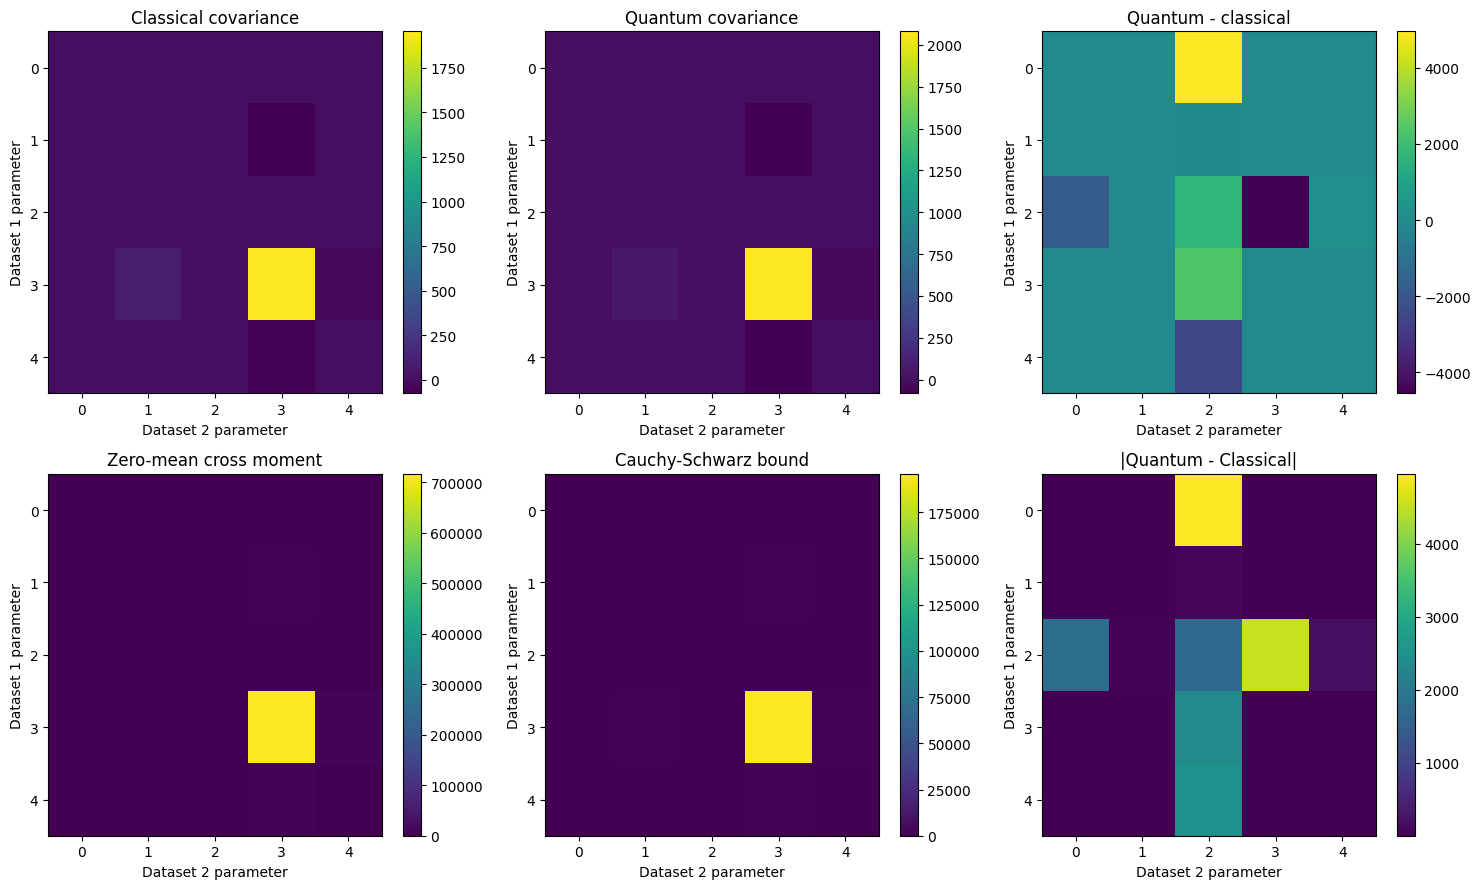

In [19]:
# ============================================================
# PLOTS
# ============================================================

fig, ax = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)


# ------------------------------------------------------------
# Standard covariance
# ------------------------------------------------------------

ax[0, 0].imshow(
    standard_covariance,
    aspect="auto"
)

ax[0, 0].set_title(
    "Classical covariance"
)

ax[0, 0].set_xlabel(
    "Dataset 2 parameter"
)

ax[0, 0].set_ylabel(
    "Dataset 1 parameter"
)

plt.colorbar(
    ax[0, 0].images[0],
    ax=ax[0, 0]
)


# ------------------------------------------------------------
# Quantum covariance
# ------------------------------------------------------------

ax[0, 1].imshow(
    quantum_covariance,
    aspect="auto"
)

ax[0, 1].set_title(
    "Quantum covariance"
)

ax[0, 1].set_xlabel(
    "Dataset 2 parameter"
)

ax[0, 1].set_ylabel(
    "Dataset 1 parameter"
)

plt.colorbar(
    ax[0, 1].images[0],
    ax=ax[0, 1]
)


# ------------------------------------------------------------
# Error
# ------------------------------------------------------------

ax[0, 2].imshow(
    covariance_error,
    aspect="auto"
)

ax[0, 2].set_title(
    "Quantum - classical"
)

ax[0, 2].set_xlabel(
    "Dataset 2 parameter"
)

ax[0, 2].set_ylabel(
    "Dataset 1 parameter"
)

plt.colorbar(
    ax[0, 2].images[0],
    ax=ax[0, 2]
)


# ------------------------------------------------------------
# Zero mean
# ------------------------------------------------------------

ax[1, 0].imshow(
    zero_mean_covariance,
    aspect="auto"
)

ax[1, 0].set_title(
    "Zero-mean cross moment"
)

ax[1, 0].set_xlabel(
    "Dataset 2 parameter"
)

ax[1, 0].set_ylabel(
    "Dataset 1 parameter"
)

plt.colorbar(
    ax[1, 0].images[0],
    ax=ax[1, 0]
)


# ------------------------------------------------------------
# Cauchy-Schwarz
# ------------------------------------------------------------

ax[1, 1].imshow(
    max_covariance,
    aspect="auto"
)

ax[1, 1].set_title(
    "Cauchy-Schwarz bound"
)

ax[1, 1].set_xlabel(
    "Dataset 2 parameter"
)

ax[1, 1].set_ylabel(
    "Dataset 1 parameter"
)

plt.colorbar(
    ax[1, 1].images[0],
    ax=ax[1, 1]
)


# ------------------------------------------------------------
# Absolute covariance error
# ------------------------------------------------------------

ax[1, 2].imshow(
    np.abs(covariance_error),
    aspect="auto"
)

ax[1, 2].set_title(
    "|Quantum - Classical|"
)

ax[1, 2].set_xlabel(
    "Dataset 2 parameter"
)

ax[1, 2].set_ylabel(
    "Dataset 1 parameter"
)

plt.colorbar(
    ax[1, 2].images[0],
    ax=ax[1, 2]
)


plt.tight_layout()

plt.show()

In [27]:
absolute_error = quantum_covariance - standard_covariance

frobenius_error = (
    np.linalg.norm(absolute_error, ord="fro")
    / np.linalg.norm(standard_covariance, ord="fro")
)

print(f"Relative Frobenius error = {frobenius_error} = {frobenius_error*100}%")

Relative Frobenius error = 0.06544143573779436 = 6.544143573779436%


In [26]:
cs_scale = np.linalg.norm(
    max_covariance,
    ord="fro"
)

cs_normalized_error = (
    np.linalg.norm(
        quantum_covariance - standard_covariance,
        ord="fro"
    )
    / cs_scale
)

print(f"Cauchy-Schwarz normalized error = {cs_normalized_error} = {cs_normalized_error*100}%")

Cauchy-Schwarz normalized error = 0.0006547599587976248 = 0.06547599587976248%


In [24]:
elementwise_normalized_error = (
    np.abs(
        quantum_covariance
        - standard_covariance
    )
    / np.maximum(
        max_covariance,
        1e-30
    )
)
elementwise_normalized_error

array([[  0.017327,   0.010602, 162.796057,   0.019686,   0.017031],
       [  0.014199,   0.005805,  28.158101,   0.007655,   0.050482],
       [101.840526,   6.418476, 106.64302 ,  44.783908,  13.86788 ],
       [  0.002931,   0.015558, 139.245074,   0.000645,   0.003529],
       [  0.022161,   0.07744 , 222.051354,   0.01302 ,   0.086597]])

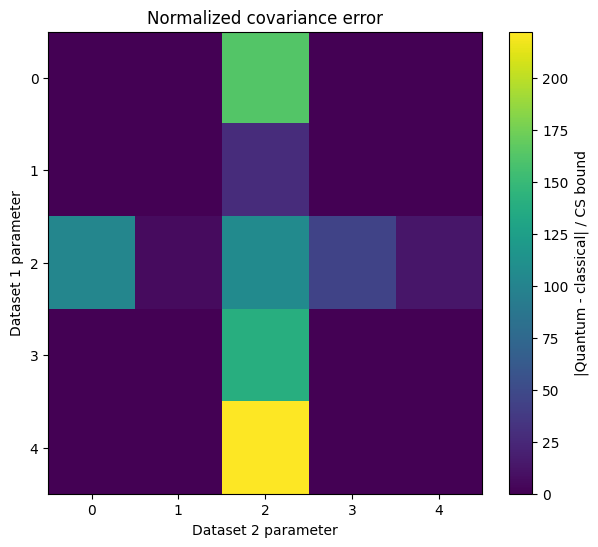

In [25]:
plt.figure(figsize=(7, 6))

plt.imshow(
    elementwise_normalized_error,
    aspect="auto",
    vmin=0
)

plt.colorbar(
    label="|Quantum - classical| / CS bound"
)

plt.xlabel("Dataset 2 parameter")
plt.ylabel("Dataset 1 parameter")
plt.title("Normalized covariance error")

plt.show()

In [28]:
delta_C = (
    quantum_covariance
    - standard_covariance
)

absolute_frobenius_error = np.linalg.norm(
    delta_C,
    ord="fro"
)

relative_frobenius_error = (
    absolute_frobenius_error
    / max(
        np.linalg.norm(
            standard_covariance,
            ord="fro"
        ),
        1e-30
    )
)

cs_frobenius_error = (
    absolute_frobenius_error
    / max(
        np.linalg.norm(
            max_covariance,
            ord="fro"
        ),
        1e-30
    )
)

max_element_error = np.max(
    np.abs(delta_C)
)

mean_element_error = np.mean(
    np.abs(delta_C)
)

In [30]:
print("========================================")
print("NORMALIZED ERROR")
print("========================================")

print(
    "Absolute Frobenius error =",
    absolute_frobenius_error
)

print(
    "Relative Frobenius error =",
    relative_frobenius_error
)

print(
    "CS-normalized Frobenius error =",
    cs_frobenius_error
)

print(
    "Maximum element error =",
    max_element_error
)

print(
    "Mean absolute element error =",
    mean_element_error
)

NORMALIZED ERROR
Absolute Frobenius error = 128.18301613264651
Relative Frobenius error = 0.06544143573779436
CS-normalized Frobenius error = 0.0006547599587976248
Maximum element error = 126.32435577107572
Mean absolute element error = 6.975394725756629


# QUANTUM WALK

In [ ]:
import numpy as np

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
)

from qiskit.circuit.library import (
    StatePreparation,
    UnitaryGate,
)


# ============================================================
# PARAMETERS
# ============================================================

params = [
    "A",
    "f",
    "t",
    "tau",
    "phi",
]

N_params = len(params)

# Number of discrete values for each parameter.
resolution_list = [
    4,
    4,
    4,
    4,
    4,
]

# Size of one elementary parameter increment.
velocity_list = [
    1,
    2,
    2,
    2,
    2,
]


# ============================================================
# PARAMETER REGISTERS
# ============================================================

qreg_wavelet_data_list = []

n_param_qubits_list = []

for param, resolution in zip(
    params,
    resolution_list
):

    n_qubits = int(
        np.ceil(
            np.log2(resolution)
        )
    )

    n_param_qubits_list.append(
        n_qubits
    )

    qreg = QuantumRegister(
        n_qubits,
        name=param
    )

    qreg_wavelet_data_list.append(qreg)


q_wavelet_data = sum(
    n_param_qubits_list
)


# ============================================================
# COVARIANCE
# ============================================================
#
# Replace this with the covariance obtained from your
# covariance-estimation circuit.
#
# This matrix must be positive semidefinite.
#
# ============================================================

Sigma_physical = np.array([
    [1.00,  0.30,  0.10, -0.20,  0.05],
    [0.30,  1.00,  0.40,  0.10, -0.15],
    [0.10,  0.40,  1.00,  0.25,  0.10],
    [-0.20, 0.10,  0.25, 1.00,  0.35],
    [0.05, -0.15, 0.10, 0.35, 1.00],
], dtype=float)


# ============================================================
# POSITIVE-SEMIDEFINITE CLEANUP
# ============================================================

def make_psd(
    Sigma,
    eigenvalue_floor=1e-12
):

    Sigma = np.asarray(
        Sigma,
        dtype=float
    )

    Sigma = (
        Sigma + Sigma.T
    ) / 2.0

    eigenvalues, eigenvectors = np.linalg.eigh(
        Sigma
    )

    eigenvalues = np.maximum(
        eigenvalues,
        eigenvalue_floor
    )

    Sigma_psd = (
        eigenvectors
        @ np.diag(eigenvalues)
        @ eigenvectors.T
    )

    return Sigma_psd


Sigma_physical = make_psd(
    Sigma_physical
)


print(
    "Eigenvalues of Sigma:",
    np.linalg.eigvalsh(Sigma_physical)
)


# ============================================================
# DISCRETE PARAMETER UNITS
# ============================================================
#
# Your quantum registers contain integer grid coordinates.
#
# If
#
#       x_i = x0_i + delta_x_i * k_i
#
# then covariance in grid coordinates is
#
#       Sigma_grid =
#           D^{-1} Sigma_physical D^{-1}.
#
# Here velocity_list defines the size of one walk step.
#
# For a more physically faithful implementation, replace
# grid_spacing_list with the actual physical spacing between
# adjacent parameter values.
#
# ============================================================

grid_spacing_list = np.array(
    velocity_list,
    dtype=float
)


D_inv = np.diag(
    1.0 / grid_spacing_list
)

Sigma_grid = (
    D_inv
    @ Sigma_physical
    @ D_inv
)


# ============================================================
# DISCRETE CORRELATED GAUSSIAN
# ============================================================
#
# We construct a finite distribution
#
#     P(delta) ~ exp(
#          -1/2 delta^T Sigma^{-1} delta
#     )
#
# over integer displacement vectors.
#
# This is the object encoded into the quantum coin.
#
# ============================================================

def make_discrete_gaussian(
    Sigma,
    cutoff=2,
):
    """
    Construct a finite discrete approximation to
    N(0, Sigma).

    Each displacement component takes values

        -cutoff, ..., 0, ..., +cutoff.

    Returns
    -------
    displacement_vectors
        Array of shape (N_moves, 5)

    probabilities
        Array of shape (N_moves,)
    """

    Sigma = make_psd(Sigma)

    Sigma_inv = np.linalg.pinv(
        Sigma
    )

    values = np.arange(
        -cutoff,
        cutoff + 1
    )

    # --------------------------------------------------------
    # Cartesian product of possible displacements.
    #
    # For cutoff=2:
    #
    # 5^5 = 3125 possible displacement vectors.
    # --------------------------------------------------------

    mesh = np.meshgrid(
        *([values] * N_params),
        indexing="ij"
    )

    displacement_vectors = np.stack(
        [
            m.reshape(-1)
            for m in mesh
        ],
        axis=1
    )

    # --------------------------------------------------------
    # Remove the zero displacement if desired.
    #
    # I KEEP IT here because it is useful:
    # the walk can remain at its current point.
    # --------------------------------------------------------

    # --------------------------------------------------------
    # Gaussian exponent
    # --------------------------------------------------------

    exponent = -0.5 * np.einsum(
        "ni,ij,nj->n",
        displacement_vectors,
        Sigma_inv,
        displacement_vectors
    )

    # Numerical stabilization
    exponent -= np.max(exponent)

    probabilities = np.exp(
        exponent
    )

    probabilities /= np.sum(
        probabilities
    )

    return (
        displacement_vectors,
        probabilities
    )


# ============================================================
# CONSTRUCT THE DISCRETE GAUSSIAN COIN
# ============================================================

cutoff = 2

displacement_vectors, displacement_probabilities = (
    make_discrete_gaussian(
        Sigma_grid,
        cutoff=cutoff
    )
)


# ============================================================
# ACTUAL COVARIANCE OF THE DISCRETIZED WALK
# ============================================================

mean_displacement = np.sum(
    displacement_vectors
    * displacement_probabilities[:, None],
    axis=0
)


centered_displacements = (
    displacement_vectors
    - mean_displacement
)


Sigma_discrete = (
    centered_displacements.T
    @ (
        centered_displacements
        * displacement_probabilities[:, None]
    )
)


print()
print(
    "=========================================="
)

print(
    "TARGET COVARIANCE"
)

print(
    "=========================================="
)

print(Sigma_grid)


print()
print(
    "=========================================="
)

print(
    "DISCRETE WALK COVARIANCE"
)

print(
    "=========================================="
)

print(Sigma_discrete)


print()
print(
    "Covariance approximation error:"
)

print(
    np.linalg.norm(
        Sigma_discrete - Sigma_grid,
        ord="fro"
    )
)


# ============================================================
# QUANTUM COIN
# ============================================================
#
# There are N_moves possible displacement vectors.
#
# We encode
#
#       |C> =
#
#       sum_delta sqrt(P(delta)) |delta>
#
# into the coin register.
#
# ============================================================

N_moves = len(
    displacement_vectors
)

n_coin = int(
    np.ceil(
        np.log2(N_moves)
    )
)

qreg_coin = QuantumRegister(
    n_coin,
    name="Coin"
)


coin_state = np.zeros(
    2**n_coin,
    dtype=complex
)

coin_state[
    :N_moves
] = np.sqrt(
    displacement_probabilities
)

coin_state /= np.linalg.norm(
    coin_state
)


coin_preparation = StatePreparation(
    coin_state
)


# ============================================================
# BUILD PERIODIC TRANSLATION MATRICES
# ============================================================
#
# For a displacement d_i:
#
#     |x_i> -> |x_i + d_i mod D_i>
#
# ============================================================

def make_shift_matrix(
    dimension,
    shift
):

    M = np.zeros(
        (dimension, dimension)
    )

    for x in range(dimension):

        y = (
            x + shift
        ) % dimension

        M[y, x] = 1.0

    return M


# ============================================================
# PRECOMPUTE ALL POSSIBLE SHIFT UNITARIES
# ============================================================

shift_cache = {}


def get_shift_unitary(
    parameter_index,
    displacement
):

    key = (
        parameter_index,
        int(displacement)
    )

    if key in shift_cache:

        return shift_cache[key]

    D = (
        2
        ** n_param_qubits_list[
            parameter_index
        ]
    )

    velocity = velocity_list[
        parameter_index
    ]

    integer_shift = (
        int(displacement)
        * int(velocity)
    )

    M = make_shift_matrix(
        D,
        integer_shift
    )

    U = UnitaryGate(
        M,
        label=(
            f"{params[parameter_index]}"
            f"{integer_shift:+d}"
        )
    )

    shift_cache[key] = U

    return U


# ============================================================
# CORRELATED SHIFT OPERATOR
# ============================================================
#
# For every displacement vector
#
#       delta = (dA, df, dt, dtau, dphi)
#
# apply all five corresponding translations conditioned on
# the coin being in |delta>.
#
# ============================================================

qc_shift = QuantumCircuit(
    *qreg_wavelet_data_list,
    qreg_coin,
    name="CorrelatedShift"
)


for move_index, displacement in enumerate(
    displacement_vectors
):

    # --------------------------------------------------------
    # Binary representation of coin state
    # --------------------------------------------------------

    binary_move = format(
        move_index,
        f"0{n_coin}b"
    )


    # --------------------------------------------------------
    # Convert arbitrary coin state to all-ones control state.
    # --------------------------------------------------------

    for k, bit in enumerate(
        binary_move
    ):

        if bit == "0":

            qc_shift.x(
                qreg_coin[k]
            )


    # --------------------------------------------------------
    # Apply all five parameter translations.
    #
    # This is the important part:
    #
    # a single coin state can simultaneously produce
    #
    #       A -> A + dA
    #       f -> f + df
    #       t -> t + dt
    #       tau -> tau + dtau
    #       phi -> phi + dphi
    #
    # Therefore correlations in Sigma produce correlated
    # parameter-space motion.
    # --------------------------------------------------------

    for parameter_index in range(
        N_params
    ):

        d = int(
            displacement[
                parameter_index
            ]
        )

        if d == 0:
            continue

        U = get_shift_unitary(
            parameter_index,
            d
        )

        controlled_U = U.control(
            num_ctrl_qubits=n_coin
        )

        qc_shift.append(
            controlled_U,
            [
                *qreg_coin,
                *qreg_wavelet_data_list[
                    parameter_index
                ]
            ]
        )


    # --------------------------------------------------------
    # Undo X gates.
    # --------------------------------------------------------

    for k, bit in enumerate(
        binary_move
    ):

        if bit == "0":

            qc_shift.x(
                qreg_coin[k]
            )


# ============================================================
# COIN MIXING OPERATOR
# ============================================================
#
# A coined quantum walk normally has:
#
#       coin preparation/mixing
#              |
#              v
#       conditional shift
#              |
#              v
#       coin mixing
#
# We use the same covariance-derived coin preparation as the
# mixing operator.
#
# IMPORTANT:
# We do NOT apply coin_preparation.inverse() because the
# shift generally entangles coin and position.
#
# ============================================================

qc_coin = QuantumCircuit(
    qreg_coin,
    name="CovarianceCoin"
)

qc_coin.append(
    coin_preparation,
    qreg_coin
)


# ============================================================
# ONE CORRELATED WALK STEP
# ============================================================

qc_timestep = QuantumCircuit(
    *qreg_wavelet_data_list,
    qreg_coin,
    name="CovarianceWalkStep"
)


# ------------------------------------------------------------
# Coin operation
# ------------------------------------------------------------

qc_timestep.append(
    qc_coin,
    qreg_coin
)


# ------------------------------------------------------------
# Correlated conditional displacement
# ------------------------------------------------------------

qc_timestep.append(
    qc_shift,
    [
        *qreg_wavelet_data_list,
        qreg_coin
    ]
)


# ============================================================
# INITIAL PARAMETER STATE
# ============================================================

initial_values = [
    0,  # A
    0,  # f
    0,  # t
    0,  # tau
    0,  # phi
]


def encode_initial_state(
    values,
    resolution_list
):

    binary_string = ""

    for value, resolution in zip(
        values,
        resolution_list
    ):

        n_qubits = int(
            np.ceil(
                np.log2(resolution)
            )
        )

        binary_string += (
            bin(value)[2:]
            .zfill(n_qubits)
        )

    return binary_string


bin_wavelet_data = encode_initial_state(
    initial_values,
    resolution_list
)

initial_integer = int(
    bin_wavelet_data,
    2
)


initial_statevector = np.zeros(
    2**q_wavelet_data
)

initial_statevector[
    initial_integer
] = 1.0


# ============================================================
# COMPLETE CIRCUIT
# ============================================================

qc = QuantumCircuit(
    *qreg_wavelet_data_list,
    qreg_coin
)


qc.initialize(
    initial_statevector,
    qreg_wavelet_data_list
)


qc.barrier()


# ============================================================
# WALK
# ============================================================

n_steps = 2

for step in range(
    n_steps
):

    qc.append(
        qc_timestep,
        [
            *qreg_wavelet_data_list,
            qreg_coin
        ]
    )

    if step != n_steps - 1:

        qc.barrier()


qc.barrier()


# ============================================================
# MEASURE ONLY AT THE END
# ============================================================

qc.measure_all()


# ============================================================
# INFORMATION
# ============================================================

print()
print(
    "=========================================="
)

print(
    "QUANTUM WALK"
)

print(
    "=========================================="
)

print(
    "Parameters:",
    params
)

print(
    "Parameter qubits:",
    q_wavelet_data
)

print(
    "Coin states:",
    N_moves
)

print(
    "Coin qubits:",
    n_coin
)

print(
    "Total qubits:",
    qc.num_qubits
)

print(
    "Number of walk steps:",
    n_steps
)

print(
    "Circuit depth:",
    qc.depth()
)


# ============================================================
# DRAW
# ============================================================

# WARNING:
# This can be extremely large for cutoff=2.
#
# qc.draw("mpl")
#
# Instead:
#
print()
print(
    qc.decompose(
        reps=1
    )
)

Eigenvalues of Sigma: [0.41166095 0.58725846 0.97273841 1.43046159 1.5978806 ]

TARGET COVARIANCE
[[ 1.      0.15    0.05   -0.1     0.025 ]
 [ 0.15    0.25    0.1     0.025  -0.0375]
 [ 0.05    0.1     0.25    0.0625  0.025 ]
 [-0.1     0.025   0.0625  0.25    0.0875]
 [ 0.025  -0.0375  0.025   0.0875  0.25  ]]

DISCRETE WALK COVARIANCE
[[ 0.90378568  0.11424815  0.03676763 -0.0797721   0.02505053]
 [ 0.11424815  0.20053029  0.07511438  0.01809678 -0.02762575]
 [ 0.03676763  0.07511438  0.20082496  0.04337383  0.01696097]
 [-0.0797721   0.01809678  0.04337383  0.20260938  0.06538926]
 [ 0.02505053 -0.02762575  0.01696097  0.06538926  0.20474199]]

Covariance approximation error:
0.15971616192547797
